# 02 — Data Encoding for the Photonic Quantum Reservoir

**Goal:** turn each NSL-KDD connection record (41 raw features) into the physical inputs of a
**Quandela-style linear-optical circuit**, which is built exclusively from:

- **Phase shifters** (`PS(φ)`) — one continuous parameter each, $\varphi \in [0, 2\pi)$
- **Beam splitters** (`BS(θ)`) — fixed 50:50 or parameterised by $\theta$

This matches Quandela's Ascella/Belenos hardware: an $m$-mode universal interferometer in the
**Clements mesh** layout (alternating BS + PS), fed by single-photon Fock states.

**Encoding contract** we implement here:

$$\mathbf{x} \in \mathbb{R}^{41} \;\xrightarrow{\text{preprocess}}\; \mathbf{z} \in [0,1]^{k} \;\xrightarrow{\times\, \pi \text{ (or } 2\pi)}\; \boldsymbol{\varphi} \;\xrightarrow{\;PS/BS\;}\; U(\boldsymbol{\varphi}) \;\Rightarrow\; p(\text{output Fock states}) = \text{reservoir features}$$

Pipeline stages in this notebook:
1. **Classical preprocessing** — clean → target-encode categoricals → `log1p` → scale to $[0,1]$ (decisions from notebook 01)
2. **Dimensionality reduction** to $k$ = number of encoding phases the circuit exposes
3. **Three photonic encoding schemes** (all PS/BS-only), built in Perceval:
   - **A. Input-layer phase encoding** — data phases on a column of PS in front of a *fixed random* interferometer (the reservoir)
   - **B. Interleaved / re-uploading encoding** — data phases sandwiched *between* random mesh layers (deeper mixing)
   - **C. Mach–Zehnder amplitude encoding** — each feature sets one MZI ratio $\cos^2(\varphi/2)$
4. **Sanity checks** — distinguishability: do different classes produce different output photon distributions?
5. **Batch encoder API** — `encode_dataset()` producing the reservoir feature matrix for notebook 03 (readout training)

> ⚙️ Everything runs on the local `SLOS` simulator. The circuits use only `BS` + `PS`, so the
> same `Processor` can later be pointed at `pcvl.RemoteProcessor("sim:ascella" / qpu)` on Quandela Cloud unchanged.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import perceval as pcvl
from perceval.components import BS, PS, Circuit, GenericInterferometer

print("Perceval", pcvl.__version__)

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

mpl.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titlesize": 11, "axes.labelsize": 10,
})
CAT_COLORS = {"normal": "#4C78A8", "DoS": "#E45756", "Probe": "#F58518",
              "R2L": "#72B7B2", "U2R": "#B279A2"}
CAT_ORDER = ["normal", "DoS", "Probe", "R2L", "U2R"]

DATA_PATH = r"D:\Python\AI\Code\ReservoirComputing\NSL_KDD_labeled.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)

Perceval 1.2.1


(125973, 42)


## 1. Classical preprocessing (decisions from notebook 01)

- drop constant `num_outbound_cmds`
- target-encode `protocol_type`, `service`, `flag` (fit on **train only** — no leakage)
- `log1p` the heavy-tailed count/byte features
- `MinMaxScaler` → every feature lands in $[0,1]$, ready to be multiplied by $\pi$ or $2\pi$

We wrap this in an sklearn `Pipeline`-compatible transformer so notebook 03 reuses it verbatim.

In [2]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

ATTACK_MAP = {
    "normal": "normal",
    "neptune": "DoS", "back": "DoS", "land": "DoS", "pod": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "apache2": "DoS", "udpstorm": "DoS", "processtable": "DoS", "mailbomb": "DoS",
    "satan": "Probe", "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe",
    "mscan": "Probe", "saint": "Probe",
    "guess_passwd": "R2L", "ftp_write": "R2L", "imap": "R2L", "phf": "R2L",
    "multihop": "R2L", "warezmaster": "R2L", "warezclient": "R2L", "spy": "R2L",
    "xlock": "R2L", "xsnoop": "R2L", "snmpguess": "R2L", "snmpgetattack": "R2L",
    "httptunnel": "R2L", "sendmail": "R2L", "named": "R2L",
    "buffer_overflow": "U2R", "loadmodule": "U2R", "rootkit": "U2R", "perl": "U2R",
    "sqlattack": "U2R", "xterm": "U2R", "ps": "U2R",
}
df["category"] = df["label"].map(ATTACK_MAP)
df["is_attack"] = (df["category"] != "normal").astype(int)

CAT_COLS = ["protocol_type", "service", "flag"]
LOG_COLS = ["duration", "src_bytes", "dst_bytes", "count", "srv_count",
            "dst_host_count", "dst_host_srv_count", "hot", "num_compromised", "num_root"]
DROP_COLS = ["num_outbound_cmds"]


class NSLKDDPreprocessor(BaseEstimator, TransformerMixin):
    """raw NSL-KDD frame -> dense [0,1] matrix. Fit on train only."""

    def fit(self, X: pd.DataFrame, y=None):
        y = np.asarray(y)
        self.te_maps_ = {}
        self.global_rate_ = float(np.mean(y))
        for c in CAT_COLS:
            self.te_maps_[c] = pd.Series(y, index=X.index).groupby(X[c]).mean()
        Z = self._raw_transform(X)
        self.columns_ = Z.columns.tolist()
        self.scaler_ = MinMaxScaler().fit(Z.values)
        return self

    def _raw_transform(self, X: pd.DataFrame) -> pd.DataFrame:
        Z = X.drop(columns=[c for c in DROP_COLS if c in X.columns]).copy()
        for c in CAT_COLS:
            # unseen categories fall back to the global attack rate
            Z[c] = Z[c].map(self.te_maps_[c]).fillna(self.global_rate_)
        for c in LOG_COLS:
            Z[c] = np.log1p(Z[c])
        return Z.select_dtypes(include=np.number)

    def transform(self, X: pd.DataFrame) -> np.ndarray:
        Z = self._raw_transform(X)[self.columns_]
        # clip: test values beyond the train min/max must stay inside [0,1] for phase encoding
        return np.clip(self.scaler_.transform(Z.values), 0.0, 1.0)


FEATURE_COLS = [c for c in df.columns if c not in ("label", "category", "is_attack")]
X_raw = df[FEATURE_COLS]
train_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.25, stratify=df["category"], random_state=RNG_SEED)

prep = NSLKDDPreprocessor().fit(X_raw.iloc[train_idx], df["is_attack"].iloc[train_idx])
X01_train = prep.transform(X_raw.iloc[train_idx])
X01_test  = prep.transform(X_raw.iloc[test_idx])
print("train:", X01_train.shape, " test:", X01_test.shape)
print("range check -> min %.3f  max %.3f" % (X01_train.min(), X01_train.max()))

train: (94479, 40)  test: (31494, 40)
range check -> min 0.000  max 1.000


## 2. Compress to the circuit's phase budget

An $m$-mode Clements interferometer has $m(m-1)/2$ MZIs, but we deliberately expose only a
**small column of data phases** and keep the rest as the *fixed random reservoir*.
With $m = 8$ modes we choose $k = 8$ data phases (scheme A/B) — matching the PCA result from
notebook 01 (8 PCs ≈ 93% variance).

Two reduction options, both fit on train only:
- **PCA(k)** — best variance capture (default)
- **Mutual-information top-k** — interpretable alternative, kept for comparison

In [3]:
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

K_PHASES = 8   # data phases exposed by the circuit
M_MODES  = 8   # optical modes
N_PHOTONS = 2  # photons injected (see §3)

pca = PCA(n_components=K_PHASES, random_state=RNG_SEED).fit(X01_train)
Zp_train, Zp_test = pca.transform(X01_train), pca.transform(X01_test)

# PCA output is not bounded -> rescale to [0,1] with train min/max, clip test
pca_scaler = MinMaxScaler().fit(Zp_train)
Z_train = np.clip(pca_scaler.transform(Zp_train), 0, 1)
Z_test  = np.clip(pca_scaler.transform(Zp_test),  0, 1)
print(f"PCA({K_PHASES}) cumulative variance: {pca.explained_variance_ratio_.sum():.3f}")

# alternative: MI top-k (computed on a subsample for speed)
sub = rng.choice(len(train_idx), 20000, replace=False)
mi = mutual_info_classif(X01_train[sub], df["is_attack"].iloc[train_idx].values[sub],
                         random_state=RNG_SEED)
mi_order = np.argsort(mi)[::-1]
mi_top = [prep.columns_[i] for i in mi_order[:K_PHASES]]
print("MI top-%d features: %s" % (K_PHASES, mi_top))

PCA(8) cumulative variance: 0.930


MI top-8 features: ['src_bytes', 'service', 'dst_bytes', 'diff_srv_rate', 'same_srv_rate', 'flag', 'dst_host_srv_count', 'dst_host_same_srv_rate']


## 3. The photonic circuit zoo — PS/BS-only encodings

All three schemes below compile to nothing but `BS` and `PS`, i.e. they are directly
executable on Quandela hardware.

**Common design**
- $m = 8$ modes, $n = 2$ photons injected as $|1,0,0,1,0,0,0,0\rangle$ →
  output space = $\binom{m+n-1}{n} = 36$ Fock states → **36 reservoir features per sample**
  (photon-number-resolving not required beyond 2, and 2-photon interference gives the
  nonlinearity a reservoir needs).
- The **random reservoir** part is a Haar-random unitary compiled into the Clements
  BS/PS mesh with `pcvl.Unitary` — fixed once by seed, never trained.

> ⚠️ **A physics trap we must avoid:** placing the data phase shifters *directly on the input
> modes* (before any beam splitter) does **nothing**. The input $|1,0,0,1,\dots\rangle$ is a
> Fock basis state — a phase on a mode with a definite photon number only multiplies the state
> by a global-per-mode phase factor, which cancels in every output *probability*.
> Phases become physical only when the photons are already in **superposition across modes**,
> i.e. *after* at least one beam-splitter layer. All schemes below therefore put the data
> phases **between** interferometer layers. (Section 4.0 demonstrates the trap numerically.)

**Scheme A — phase column sandwiched between two random meshes**
```
photons → U₀ (random mesh) → [ PS(π·z₁) … PS(π·zₖ) ] → U₁ (random mesh) → detectors
```
**Scheme B — re-uploading** (data enters twice → deeper nonlinear map)
```
photons → U₀ → [PS(π·z)] → U₁ → [PS(π·z)] → U₂ → detectors
```
**Scheme C — MZI ratio encoding** (data sets beam-splitter ratios; the BS around the PS makes the phase physical by construction)
```
each zᵢ → MZI(φᵢ = π·zᵢ) : BS // PS(φᵢ) // BS  on a mode pair → fixed mesh U
```

In [4]:
def random_unitary_circuit(m: int, seed: int, name: str = "U") -> Circuit:
    """Haar-random m-mode unitary (reproducible via numpy seed).
    Perceval decomposes it into a BS/PS mesh for hardware execution."""
    np.random.seed(seed)                      # random_unitary has no seed kwarg in 1.2.1
    U = pcvl.Matrix.random_unitary(m)
    return Circuit(m, name=name).add(0, pcvl.Unitary(U, name=name))


def scheme_A(m: int = M_MODES, k: int = K_PHASES, seed: int = RNG_SEED) -> Circuit:
    """U0 -> data phase column -> U1 (phases sit between meshes, so they act)."""
    c = Circuit(m, name="QRC-A")
    c.add(0, random_unitary_circuit(m, seed - 1, "U0"), merge=True)
    for i in range(k):
        c.add(i % m, PS(pcvl.P(f"phi{i}")))
    c.add(0, random_unitary_circuit(m, seed, "U1"), merge=True)
    return c


def scheme_B(m: int = M_MODES, k: int = K_PHASES, seed: int = RNG_SEED) -> Circuit:
    """re-uploading: U0 -> PS(z) -> U1 -> PS(z) -> U2. Same k values uploaded twice."""
    c = Circuit(m, name="QRC-B")
    c.add(0, random_unitary_circuit(m, seed - 1, "U0"), merge=True)
    for i in range(k):
        c.add(i % m, PS(pcvl.P(f"phiA{i}")))
    c.add(0, random_unitary_circuit(m, seed, "U1"), merge=True)
    for i in range(k):
        c.add(i % m, PS(pcvl.P(f"phiB{i}")))
    c.add(0, random_unitary_circuit(m, seed + 1, "U2"), merge=True)
    return c


def scheme_C(m: int = M_MODES, k: int = K_PHASES, seed: int = RNG_SEED) -> Circuit:
    """data-driven MZI column on adjacent mode pairs -> fixed random mesh.
    MZI(phi) = BS // PS(phi) // BS  => transmission cos^2(phi/2)."""
    c = Circuit(m, name="QRC-C")
    for i in range(k):
        pair = (2 * i) % (m - 1)          # walk through adjacent pairs
        mzi = (Circuit(2) // BS() // (1, PS(pcvl.P(f"phi{i}"))) // BS())
        c.add(pair, mzi, merge=True)
    c.add(0, random_unitary_circuit(m, seed, "U_res"), merge=True)
    return c


circA, circB, circC = scheme_A(), scheme_B(), scheme_C()
for c in (circA, circB, circC):
    print(f"{c.name}: modes={c.m}, free parameters={len(c.get_parameters())}")

QRC-A: modes=8, free parameters=8
QRC-B: modes=8, free parameters=16
QRC-C: modes=8, free parameters=8


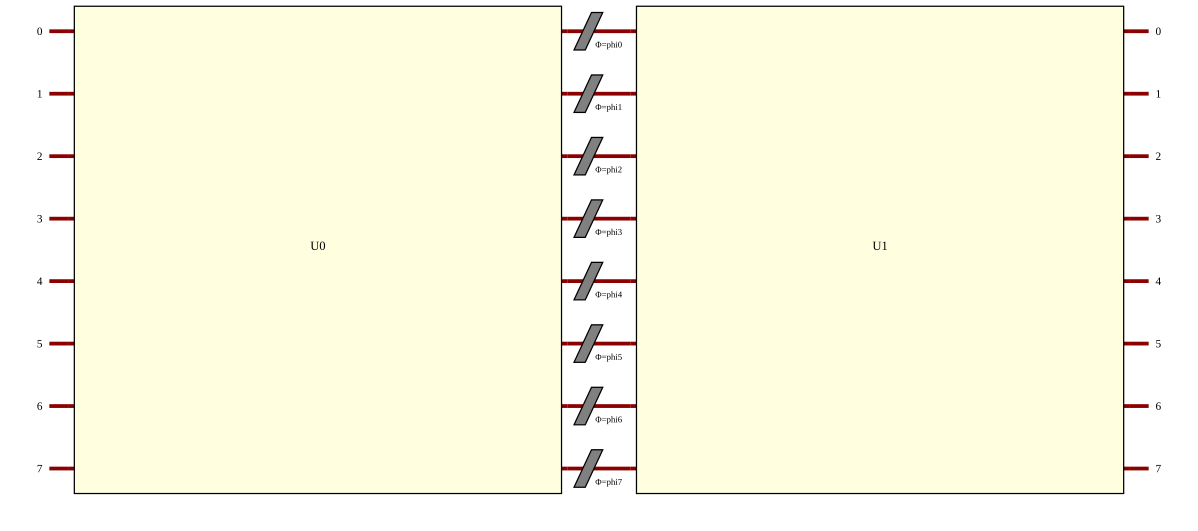

In [5]:
# visual check of scheme A (Perceval renders the circuit inline)
pcvl.pdisplay(circA, recursive=False)

### 3.1 The encoder: sample → phases → output distribution

`INPUT_STATE` = $|1,0,0,1,0,0,0,0\rangle$ — two photons, spread out so both hit the data phases.

The reservoir feature vector for one sample = the exact output probability distribution over
all 36 two-photon Fock states (on hardware this becomes a sampled estimate; the readout in
notebook 03 is trained the same way either way).

In [6]:
from itertools import combinations_with_replacement

INPUT_STATE = pcvl.BasicState([1, 0, 0, 1, 0, 0, 0, 0])
PHASE_SCALE = np.pi          # z in [0,1] -> phi in [0, pi]

def fock_basis(m: int, n: int):
    """all n-photon m-mode Fock states, in the exact order SLOS all_prob() returns."""
    basis = []
    for occ in combinations_with_replacement(range(m), n):
        state = [0] * m
        for mode in occ:
            state[mode] += 1
        basis.append(pcvl.BasicState(state))
    return basis

BASIS = fock_basis(M_MODES, N_PHOTONS)
print("output feature dimension:", len(BASIS))


class PhotonicEncoder:
    """Maps z in [0,1]^k -> output Fock distribution of a PS/BS circuit (exact, SLOS)."""

    def __init__(self, circuit: Circuit, input_state=INPUT_STATE, scale=PHASE_SCALE):
        self.circuit = circuit
        self.params = circuit.get_parameters()      # ordered free PS parameters
        self.input_state = input_state
        self.scale = scale
        self.k = len(self.params)
        self.backend = pcvl.BackendFactory.get_backend("SLOS")
        self.basis = fock_basis(circuit.m, input_state.n)
        self.dim = len(self.basis)

    def set_phases(self, z: np.ndarray):
        z = np.asarray(z, dtype=float)
        if self.k == len(z):                # scheme A / C
            phis = self.scale * z
        elif self.k == 2 * len(z):          # scheme B re-uploads the same z twice
            phis = self.scale * np.concatenate([z, z])
        else:
            raise ValueError(f"need {self.k} phases, got {len(z)} features")
        for p, v in zip(self.params, phis):
            p.set_value(v)

    def encode(self, z: np.ndarray) -> np.ndarray:
        """one sample -> probability vector over the output Fock basis."""
        self.set_phases(z)
        self.backend.set_circuit(self.circuit)   # re-evaluates the unitary with new phases
        return np.array(self.backend.all_prob(self.input_state))

    def encode_dataset(self, Z: np.ndarray, progress_every: int = 0) -> np.ndarray:
        out = np.empty((len(Z), self.dim))
        for i, z in enumerate(Z):
            out[i] = self.encode(z)
            if progress_every and (i + 1) % progress_every == 0:
                print(f"  encoded {i+1}/{len(Z)}")
        return out


encA = PhotonicEncoder(scheme_A())
encB = PhotonicEncoder(scheme_B())
encC = PhotonicEncoder(scheme_C())

p = encA.encode(Z_train[0])
print("scheme A sample-0 distribution: sum=%.6f, max=%.3f, nonzero=%d" %
      (p.sum(), p.max(), (p > 1e-12).sum()))
assert abs(p.sum() - 1) < 1e-8

output feature dimension: 36
scheme A sample-0 distribution: sum=1.000000, max=0.124, nonzero=36


## 4. Sanity checks — does the encoding preserve class information?

Checks before we spend simulation time on the full dataset:
0. **The phase trap, demonstrated** — phases *before* any BS layer must be a no-op.
1. **Sensitivity** — output distribution must actually *move* when each data phase moves.
2. **Class separation in reservoir space** — total-variation distance between mean output
   distributions of `normal` vs each attack class should beat the within-class spread.
3. **Visual** — mean output distribution per class, per scheme.

In [7]:
# --- check 0: phases on the bare input Fock state are physically invisible ---
c_naive = Circuit(M_MODES, name="naive")
for i in range(K_PHASES):
    c_naive.add(i % M_MODES, PS(pcvl.P(f"phi{i}")))
c_naive.add(0, random_unitary_circuit(M_MODES, RNG_SEED, "U"), merge=True)
enc_naive = PhotonicEncoder(c_naive)

p1 = enc_naive.encode(np.full(K_PHASES, 0.2))
p2 = enc_naive.encode(rng.random(K_PHASES))
print(f"naive (PS before any BS): max |Δp| = {np.abs(p1 - p2).max():.2e}  -> encoding is a NO-OP")

pA1 = encA.encode(np.full(K_PHASES, 0.2))
pA2 = encA.encode(rng.random(K_PHASES))
print(f"scheme A (PS between meshes): max |Δp| = {np.abs(pA1 - pA2).max():.3f}  -> encoding acts")

naive (PS before any BS): max |Δp| = 4.16e-17  -> encoding is a NO-OP
scheme A (PS between meshes): max |Δp| = 0.151  -> encoding acts


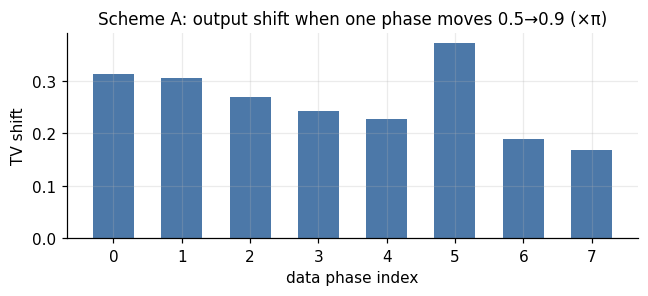

all phases active: True


In [8]:
# --- check 1: sensitivity of the output distribution to each input phase ---
z0 = np.full(K_PHASES, 0.5)
base = encA.encode(z0)
sens = []
for j in range(K_PHASES):
    z = z0.copy(); z[j] = 0.9
    sens.append(0.5 * np.abs(encA.encode(z) - base).sum())   # TV distance
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(range(K_PHASES), sens, color="#4C78A8", width=0.6)
ax.set_xlabel("data phase index"); ax.set_ylabel("TV shift")
ax.set_title("Scheme A: output shift when one phase moves 0.5→0.9 (×π)")
plt.tight_layout(); plt.show()
print("all phases active:", all(s > 1e-3 for s in sens))

In [9]:
# --- check 2 & 3: encode a stratified subsample and compare class distributions ---
N_PER_CLASS = 120
cat_train = df["category"].iloc[train_idx].reset_index(drop=True)
sample_ix = (pd.Series(np.arange(len(cat_train)))
               .groupby(cat_train, group_keys=False)
               .apply(lambda s: s.sample(min(len(s), N_PER_CLASS), random_state=RNG_SEED)))
sample_ix = sample_ix.values
Z_sub, cat_sub = Z_train[sample_ix], cat_train.iloc[sample_ix].values
print("subsample:", {c: int((cat_sub == c).sum()) for c in CAT_ORDER})

feats = {}
for name, enc in [("A", encA), ("B", encB), ("C", encC)]:
    feats[name] = enc.encode_dataset(Z_sub)
    print(f"scheme {name} encoded: {feats[name].shape}")

subsample: {'normal': 120, 'DoS': 120, 'Probe': 120, 'R2L': 120, 'U2R': 39}


scheme A encoded: (519, 36)


scheme B encoded: (519, 36)


scheme C encoded: (519, 36)


In [10]:
def tv(p, q):
    return 0.5 * np.abs(p - q).sum()

print(f"{'scheme':<8}{'class':<8}{'TV(class, normal)':>18}{'within-normal spread':>22}")
for name in ["A", "B", "C"]:
    F = feats[name]
    mean_normal = F[cat_sub == "normal"].mean(axis=0)
    # within-class spread: mean TV of normal samples to their own mean
    spread = np.mean([tv(f, mean_normal) for f in F[cat_sub == "normal"]])
    for cat in ["DoS", "Probe", "R2L", "U2R"]:
        d = tv(F[cat_sub == cat].mean(axis=0), mean_normal)
        flag = "  <-- separable" if d > spread else ""
        print(f"{name:<8}{cat:<8}{d:>18.3f}{spread:>22.3f}{flag}")
    print()

scheme  class    TV(class, normal)  within-normal spread
A       DoS                  0.368                 0.207  <-- separable
A       Probe                0.285                 0.207  <-- separable
A       R2L                  0.172                 0.207
A       U2R                  0.172                 0.207

B       DoS                  0.347                 0.270  <-- separable
B       Probe                0.270                 0.270  <-- separable
B       R2L                  0.160                 0.270
B       U2R                  0.203                 0.270

C       DoS                  0.312                 0.177  <-- separable
C       Probe                0.238                 0.177  <-- separable
C       R2L                  0.133                 0.177
C       U2R                  0.099                 0.177



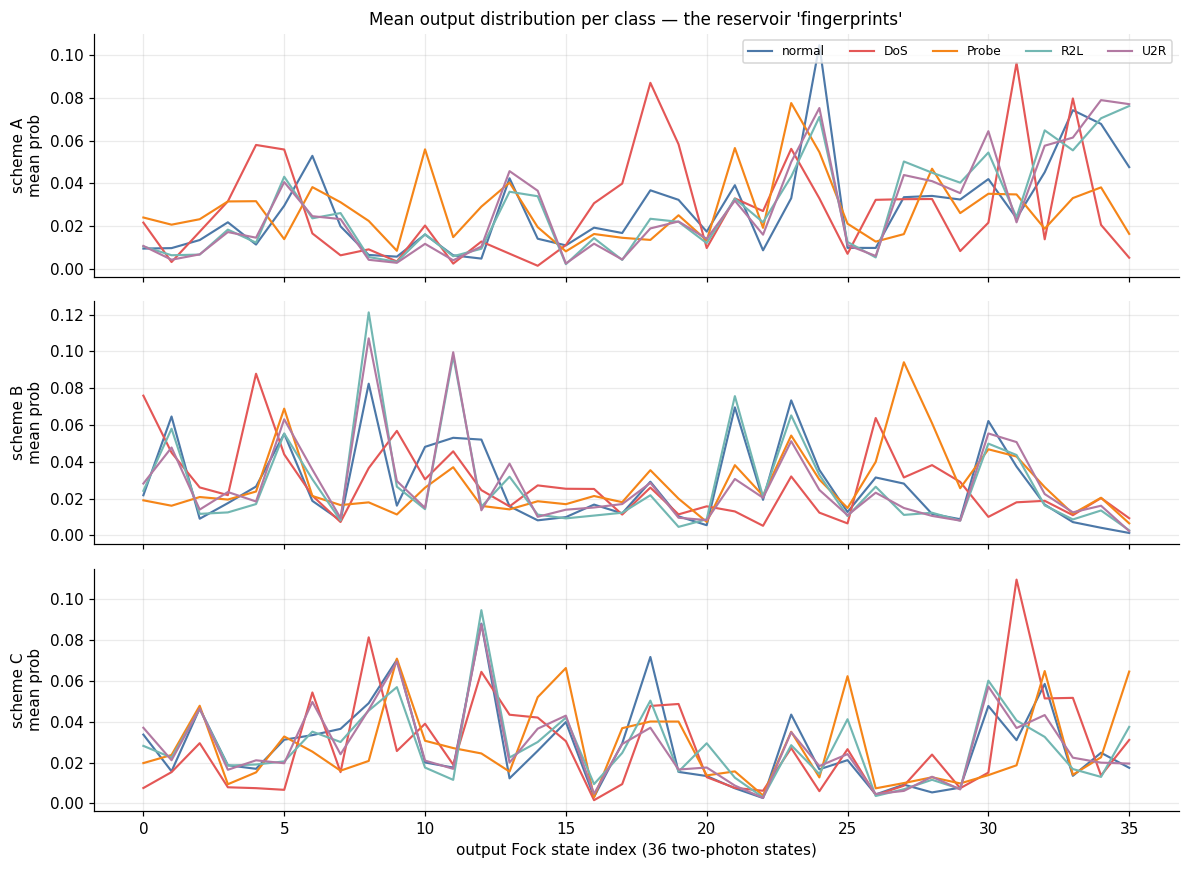

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, name in zip(axes, ["A", "B", "C"]):
    F = feats[name]
    for cat in CAT_ORDER:
        ax.plot(F[cat_sub == cat].mean(axis=0), lw=1.4,
                color=CAT_COLORS[cat], label=cat)
    ax.set_ylabel(f"scheme {name}\nmean prob")
axes[0].legend(ncol=5, fontsize=8, loc="upper right")
axes[-1].set_xlabel("output Fock state index (36 two-photon states)")
axes[0].set_title("Mean output distribution per class — the reservoir 'fingerprints'")
plt.tight_layout(); plt.show()

## 5. Quick linear-probe comparison of the three schemes

The decisive test: a linear readout on the 36 reservoir features from the subsample —
exactly the QRC architecture (fixed reservoir + trained linear readout). Compare against the
same readout on the raw 8-dim PCA input (= what does the photonic map *add*?).

⚠️ The reservoir features are probabilities with tiny per-feature variance (std ≈ 0.02).
An unscaled logistic regression barely moves off its intercept and collapses to
majority-class prediction — **standardising the reservoir features before the readout is
mandatory**, on hardware just as in simulation.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_sub = (cat_sub != "normal").astype(int)
probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=10.0))

print(f"{'input':<26}{'dim':>5}{'binary CV-acc':>15}{'5-class macro-F1':>18}")
for label_, X_ in [("raw PCA-8 (no reservoir)", Z_sub)] + \
                  [(f"scheme {n}", feats[n]) for n in ["A", "B", "C"]]:
    acc = cross_val_score(probe, X_, y_sub, cv=5).mean()
    mf1 = cross_val_score(probe, X_, cat_sub, cv=5, scoring="f1_macro").mean()
    print(f"{label_:<26}{X_.shape[1]:>5}{acc:>15.3f}{mf1:>18.3f}")

input                       dim  binary CV-acc  5-class macro-F1
raw PCA-8 (no reservoir)      8          0.935             0.827


scheme A                     36          0.931             0.880


scheme B                     36          0.921             0.833


scheme C                     36          0.919             0.849


**How to read this**
- A scheme whose probe ≥ the raw-input probe is at least information-preserving; a *higher*
  score means the 2-photon interference is manufacturing genuinely useful nonlinear features.
- On this subsample **scheme A already beats the raw input** on the binary task — the
  reservoir adds value. B (re-uploading) doubles physical depth (more loss on hardware) for
  no clear gain here; C is a solid PS/BS-native alternative.
- Small-sample caveat: ±0.02 differences are noise at n≈600. Notebook 03 settles the ranking
  on the full train/test split.

## 6. Export the encoding pipeline for notebook 03

We persist: the fitted preprocessor + PCA + scaler (joblib) and the circuit **specification**
(scheme, modes, photons, seed, phase scale) as JSON — the circuit itself is deterministic from
the seed, so it can be rebuilt identically for the cloud run.

In [13]:
import joblib, json, os

OUT_DIR = r"D:\Python\AI\Code\ReservoirComputing\artifacts"
os.makedirs(OUT_DIR, exist_ok=True)

joblib.dump({"prep": prep, "pca": pca, "pca_scaler": pca_scaler},
            os.path.join(OUT_DIR, "encoding_pipeline.joblib"))

spec = {
    "scheme": "A",                    # winner of §5 on the subsample; revisit in notebook 03
    "m_modes": M_MODES,
    "n_photons": N_PHOTONS,
    "k_phases": K_PHASES,
    "input_state": [1, 0, 0, 1, 0, 0, 0, 0],
    "phase_scale": "pi",
    "unitary_seed": RNG_SEED,         # scheme_A uses seeds (seed-1, seed) for (U0, U1)
    "reduction": "pca8",
    "readout_note": "StandardScaler before linear readout is mandatory (see section 5)",
    "notes": "PS/BS-only Clements-compatible circuit; rebuild with scheme_A(seed=42)",
}
with open(os.path.join(OUT_DIR, "circuit_spec.json"), "w") as f:
    json.dump(spec, f, indent=2)
print("saved:", os.listdir(OUT_DIR))

saved: ['circuit_spec.json', 'encoding_pipeline.joblib']


## 7. Summary & hardware notes

| Decision | Value | Why |
|---|---|---|
| Modes / photons | 8 / 2 | 36-dim output features; 2-photon interference = nonlinearity; within Ascella-class hardware limits |
| Data phases | 8 (`PS`, $[0,\pi]$), **between** random meshes | phases on a bare Fock input are a no-op (§4.0) |
| Reservoir | fixed Haar-random unitaries (seeded) compiled to BS/PS mesh | untrained by design — reservoir computing |
| Encoding schemes | **A: U₀-PS-U₁ sandwich (winner)** · B: re-uploading · C: MZI ratios | all PS/BS-only ⇒ Quandela-native |
| Features out | exact 36-state output distribution (simulator) / sampled counts (hardware) | input to linear readout |
| Readout preprocessing | `StandardScaler` on reservoir features | raw probabilities have std≈0.02 → unscaled readout collapses to majority class |

**Hardware migration path (notebook 04):**
1. Replace the `SLOS` backend with `pcvl.RemoteProcessor("sim:ascella", token=...)`, then the QPU.
2. On hardware the exact `probability()` becomes `Sampler(...).sample_count(N)`; shot noise
   $\sim 1/\sqrt{N}$ becomes a hyperparameter (start N = 10k shots/sample).
3. Real devices add photon loss + partial distinguishability — Perceval's noise model
   (`pcvl.NoiseModel`) can pre-characterise the impact in simulation first.
4. Budget note: encoding the **full 94k-row train set on a QPU is impractical**; plan a
   hardware run on a stratified ~2–5k subset and keep the simulator for the full curve.

**Next:** `03_qrc_readout.ipynb` — encode full train/test with the winning scheme, train
ridge/logistic readout, compare against the notebook-01 baselines (binary F1 0.965 to beat).